# Images Ramen breaks: does its step point away from the true class?

**Question.** Ramen turns some zero-shot-right images wrong ("broken" images). On those images, how does Ramen's
update direction $\hat g_i$ line up with the gradient of the **cross-entropy toward the true label** $g^{CE}_i$, and
is that different from the zero-shot-right images Ramen keeps right **at the same zero-shot confidence**?

**Why this matters.** Notebooks 01–03 found that on broken images the step's cosine with $g^{CE}$ is near zero
(DomainNet median $+0.003$). But broken images are also the low-confidence ones, so "Ramen's direction is bad there"
and "these images flip under any small push" were not separated. Here every comparison is made at matched
confidence, and the update is split into the parts that come from different memory queues.

**This is an analysis of an oracle measurement, not a method.** $g^{CE}_i$ uses the ground-truth label. The probe
run `ga_probe` predicts exactly what Ramen predicts (section 3); nothing here changes a prediction, so there is no
accuracy gain and no noise-floor test.

**Not pre-registered.** The probe data were already collected and the broken-image medians were already seen in
notebooks 01–03. The questions below were written before these tables were computed, but the analysis is
exploratory and single-seed.
- **Q1** On broken images, is Ramen's sign step less aligned with $g^{CE}$ than on kept images with the same
  zero-shot confidence? How often does it point away ($\cos < 0$)?
- **Q2** Does alignment predict breaking beyond confidence? (AUROC within confidence bins; confidence alone vs
  confidence + alignment.)
- **Q3** Which part of the update is missing on broken images: the image's own entry, its own queue, or the other
  queues?
- **Q4** Where and when: by domain, over the stream (DomainNet fp16 priority freeze), and which classes Ramen moves
  broken images to.
- **Q5** (section 6, added 2026-11-19) What does the true-label loss look like around the zero-shot parameters
  $\theta_0$ and Ramen's adapted $\theta_i$, and around the embeddings before ($z_0$) and after ($z_1$) adaptation?
  Along Ramen's step, how does the loss compare with the oracle step and a random step of the same length?

**Data.** Seed 0, mixed stream, batch 100, `cfg/<dataset>/Ramen.yaml` unchanged:
| dataset | images | classes | model | memory |
|---|---|---|---|---|
| EuroSAT | 27,000 (1 domain) | 10 | CLIP ViT-B/16 | $K = 7{,}500$, $k = 50$, $\beta = 5$ |
| ImageNet-C 5K | 75,000 (5,000 photos × 15 corruptions, severity 5) | 1,000 | CLIP ViT-B/16 | $K = 75$, $k = 1$, $\beta = 0$ |
| DomainNet | 596,006 (6 domains) | 345 | CLIP ViT-B/32 | $K = 300$, $k = 10$, $\beta = 5$ |

**Seeds.** Seed 0 only. A seed sets the stream order (and so what the memory holds when each image arrives).

**How the runs were produced.** `run_grad_alignment.py <dataset> 0` (README "How to run"); cached in
`new_experiments/results/<ds>_<model>_mixed_nall_bs100_s0_ga_probe{,_stats}.pkl`. Section 6 uses a second replay of
the same stream, `run_landscape.py <dataset> 0` (run `ga_landscape`, method `RamenLandscapeProbe`): for 50 images
per outcome group, drawn at random (numpy seed 0) from the `ga_probe` frame before the run and saved in
`landscape_selection_<dataset>_s0.json`, it evaluates the loss on a grid of parameters around $\theta_0$ and
$\theta_i$. This notebook only reads the cached runs: `broken_analysis.py` / `landscape_analysis.py` (tables),
`broken_plots.py` / `landscape_plots.py` (figures), written by `make_broken_notebook.py`.

**What counts as a result.** Descriptive: medians and means per group, with counts. "Kept (matched)" = the kept
images reweighted to the broken images' distribution of zero-shot $p(\text{true})$ (20 quantile bins).

**How to read this notebook.** 1 setup · 2 the data · 3 sanity check · 4 results (Q1, Q2) · 5 mechanism (Q3, Q4) ·
6 loss landscape (Q5) · 7 interpretation · 8 glossary.


## Method: what is measured

**Ramen (baseline, unchanged).** Batch of $B = 100$ images; $\theta_0$ = LayerNorm affine parameters of the CLIP
image encoder ($D$ numbers). $z_i$ normalised feature, $p_i = \operatorname{softmax}(100\, z_i^\top W)$,
$\hat y_i = \arg\max_c p_{ic}$, $H_i = -\sum_c p_{ic}\log p_{ic}$, $g_i = \nabla_\theta H_i|_{\theta_0}$.
1. Write $(z_i, g_i, H_i, \pi_i)$ to queue $\mathcal M_{\hat y_i}$ (before retrieval; priority $\pi_i$ = arrival
   index in fp16; a full queue replaces its lowest priority only if $\pi_i$ is larger).
2. Retrieve $\mathcal N_k^c(z_i)$, the $k$ nearest entries of every non-empty queue $c \in C_i$,
   $d_{ij} = \lVert z_i - z_j\rVert_2$.
3. $\displaystyle \hat g_i = \frac{1}{|C_i|}\sum_{c \in C_i}\sum_{j \in \mathcal N_k^c(z_i)} e^{-H_j} e^{-\beta d_{ij}} g_j$
4. $\theta_i = \theta_0 - \eta\,\operatorname{sign}(\hat g_i)$; predict $\hat y^{R}_i$ under $\theta_i$; reset.

**Oracle direction (uses the true label $y_i$).**
$g^{CE}_i = \nabla_\theta\big[-\log p_{i y_i}\big]\big|_{\theta_0}$. Moving along $-g^{CE}_i$ raises $p(\text{true})$.

**Groups (zero-shot-right images only, $\hat y_i = y_i$).**
$\text{broken} = \{i : \hat y_i = y_i,\ \hat y^R_i \ne y_i\}$,
$\text{kept} = \{i : \hat y_i = y_i,\ \hat y^R_i = y_i\}$.
Kept (matched): weight $w_i = n_{\text{broken}}(b_i) / n_{\text{kept}}(b_i)$, with $b_i$ the quantile bin (20 bins)
of $p_{i y_i}$, so the weighted kept images have the broken images' confidence distribution.

**Per-image quantities** (all from the probe; every one except the last uses $y_i$):
- $\cos(\operatorname{sign}\hat g_i, g^{CE}_i)$, the direction Ramen actually moves. To first order the step
  changes the true-class loss by $-\eta\sqrt D\,\lVert g^{CE}_i\rVert\cos(\operatorname{sign}\hat g_i, g^{CE}_i)$, so
  a negative cosine lowers $p(\text{true})$.
- $\cos(\hat g_i, g^{CE}_i)$ (the update before the sign), $\cos(g_i, g^{CE}_i)$ (the image's own entropy gradient).
- Control $\cos(\hat g_i, g^{CE}_{i-1})$, another image's oracle gradient: about $+0.04$ to $+0.16$ for every
  image, a direction all images share. Use it, not 0, as the "no image-specific information" level.
- Decomposition $\hat g_i = s_i + t_i + o_i$ (for zero-shot-right images the zero-shot queue *is* the true-class
  queue, so the zero-shot-queue part of notebooks 01–03 is 0): $s_i$ = own entry ($j = i$, zero if not stored),
  $t_i$ = other entries of $\mathcal M_{y_i}$, $o_i$ = all other queues. Each part's share
  $\langle v_i, g^{CE}_i\rangle / (\lVert\hat g_i\rVert\lVert g^{CE}_i\rVert)$; the three sum to
  $\cos(\hat g_i, g^{CE}_i)$.
- Label-free: $\cos(\hat g_i, g_i)$, the update vs the image's own entropy gradient.

| symbol | meaning | code (`ga_methods.py` field) | value |
|---|---|---|---|
| $\hat g_i$ | Ramen's update | `cos_update`, `cos_step` | — |
| $g^{CE}_i$ | **oracle** true-label CE gradient | `RamenGradientProbe.oracle_ce_gradient` | — |
| $g_i$ | own entropy gradient | `cos_self` | — |
| $s_i, t_i, o_i$ | own entry, own queue, other queues | `part_self`, `part_true`, `part_other` | — |
| $\pi_i$ fp16 | priority; saturates after ~65k inserts | `Ramen.counter` | default (fp16), as in Ramen |
| $\eta$ | step size | `lr` | 0.01 |
| $w_i$ | confidence-matching weight | `BrokenImages.w_matched` | 20 bins |

**Loss-landscape slices (section 6; ORACLE: the loss and one axis use $y_i$).** Loss
$L_i(\theta) = -\log p_{y_i}(x_i; \theta)$, the true-label cross-entropy of image $i$ under LayerNorm parameters
$\theta$; also the entropy $H_i(\theta)$ and the predicted class.
- *Parameter space.* $u_i = \theta_i - \theta_0 = -\eta\operatorname{sign}(\hat g_i)$, Ramen's actual step (read from
  the parameters after SignSGD); $o_i = -\eta\operatorname{sign}(g^{CE}_i)$, the oracle SignSGD step on the
  true-label loss; $r_i = -\eta\operatorname{sign}(\xi_i)$, $\xi_i \sim \mathcal N(0, I)$, a random sign step
  (control). All three have length $\eta\sqrt D$. Plane: $e_1 = u_i$,
  $e_2 = \lVert u_i\rVert\, \dfrac{o_i - \frac{\langle o_i, u_i\rangle}{\lVert u_i\rVert^2} u_i}{\lVert \cdot \rVert}$,
  grid $\theta(a, b) = \theta_0 + a e_1 + b e_2$, $a \in [-1, 2.5]$, $b \in [-1, 1.75]$, step $0.125$. So
  $\theta_0 = (0, 0)$, $\theta_i = (1, 0)$, and the oracle step sits at
  $\big(\langle o_i, u_i\rangle / \lVert u_i\rVert^2,\ \lVert o_{i\perp}\rVert / \lVert u_i\rVert\big)$.
  Lines: $L_i(\theta_0 + t v)$ for $v \in \{u_i, o_i, r_i\}$, $t \in [-1, 3]$, step $0.1$; $t = 1$ is one step.
- *Embedding space* (frozen text head, offline). $z_0$ = zero-shot feature, $z_1$ = feature under $\theta_i$.
  $t_1 = z_1 - z_0$; $t_2$ = the head's true-class ascent direction at $z_0$, $w_{y_i} - \sum_c p_{ic} w_c$, made
  orthogonal to $z_0$ and $t_1$ and rescaled to $\lVert t_1\rVert$;
  $z(a, b) = \dfrac{z_0 + a t_1 + b t_2}{\lVert z_0 + a t_1 + b t_2 \rVert}$, loss
  $-\log \operatorname{softmax}(100\, z(a, b)^\top W)_{y_i}$. So $z_0 = (0, 0)$ and $z_1 = (1, 0)$.

| symbol | meaning | code | value |
|---|---|---|---|
| $u_i, o_i, r_i$ | Ramen / oracle / random step | `RamenLandscapeProbe.landscape` | length $0.01\sqrt D$ |
| $a, b$ | slice coordinates | `landscape.GRID_A`, `GRID_B` | 29 × 23 points |
| $t$ | line coordinate | `landscape.LINE_T` | 41 points |
| — | images per outcome group | `landscape_experiment.N_PER_GROUP` | 50 (fewer if the group is smaller) |


## 1. Setup

In [1]:
import os, sys, warnings
os.environ['CUDA_VISIBLE_DEVICES'] = ''
warnings.filterwarnings('ignore')
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from ga_experiment import GradAlignmentExperiment
from broken_analysis import BrokenImages, class_names
import broken_plots as bp
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 80)
%matplotlib inline

DATASETS = ['EuroSAT', 'ImageNetC5K', 'DomainNet']           # small -> large label space
exps = {ds: GradAlignmentExperiment(ds, seed=0).run_all() for ds in DATASETS}   # cached; no GPU
bis = {ds: BrokenImages(e.frame()) for ds, e in exps.items()}

from landscape_experiment import LandscapeExperiment
from landscape_analysis import Landscapes
import landscape_plots as lp
lexps = {ds: LandscapeExperiment(ds, seed=0) for ds in DATASETS}
for e in lexps.values():
    e.run_all()                       # NoAdapt, Ramen, ga_probe and ga_landscape, all cached; no GPU
Ls = {ds: Landscapes(e.landscape_records(), e.text_feature()) for ds, e in lexps.items()}

## 2. The data

The denominators for everything below: zero-shot-right images per dataset and how many Ramen breaks. On DomainNet the fp16 priority counter saturates, so most images after ~165k are not stored in memory.

In [2]:
display(pd.DataFrame({ds: b.counts() for ds, b in bis.items()}))

,EuroSAT,ImageNetC5K,DomainNet
images,"27,000","75,000","596,006"
zero-shot right,"12,984 of 27,000 (48.1%)","20,460 of 75,000 (27.3%)","314,840 of 596,006 (52.8%)"
broken by Ramen (of zero-shot right),"1,082 of 12,984 (8.3%)","2,860 of 20,460 (14.0%)","10,302 of 314,840 (3.3%)"
kept right by Ramen (of zero-shot right),"11,902 of 12,984 (91.7%)","17,600 of 20,460 (86.0%)","304,538 of 314,840 (96.7%)"
broken images with own entry stored,"1,082 of 1,082 (100.0%)","2,860 of 2,860 (100.0%)","2,386 of 10,302 (23.2%)"


Per domain (zero-shot-right images; medians):

In [3]:
for ds in ['ImageNetC5K', 'DomainNet']:
    print(ds); display(bis[ds].by_domain().round(3))

ImageNetC5K


,zero-shot right,broken,"median p_zs(true), broken","median cos(sign step, g_ce), broken","median cos(sign step, g_ce), kept",broken with cos < 0
domain,,,,,,
gaussian_noise,750,180 of 750 (24.0%),0.213,0.050,0.081,37 of 180 (20.6%)
shot_noise,844,215 of 844 (25.5%),0.204,0.039,0.077,41 of 215 (19.1%)
impulse_noise,766,169 of 766 (22.1%),0.243,0.024,0.069,46 of 169 (27.2%)
defocus_blur,1283,"253 of 1,283 (19.7%)",0.202,0.026,0.054,53 of 253 (20.9%)
glass_blur,843,153 of 843 (18.1%),0.178,0.032,0.063,27 of 153 (17.6%)
motion_blur,1343,"255 of 1,343 (19.0%)",0.241,0.031,0.060,55 of 255 (21.6%)
zoom_blur,1227,"195 of 1,227 (15.9%)",0.184,0.029,0.057,29 of 195 (14.9%)
snow,1699,"207 of 1,699 (12.2%)",0.278,0.012,0.038,67 of 207 (32.4%)
frost,1652,"214 of 1,652 (13.0%)",0.297,0.005,0.037,90 of 214 (42.1%)


DomainNet


,zero-shot right,broken,"median p_zs(true), broken","median cos(sign step, g_ce), broken","median cos(sign step, g_ce), kept",broken with cos < 0
domain,,,,,,
clipart,33326,"1,033 of 33,326 (3.1%)",0.345,0.003,0.054,"481 of 1,033 (46.6%)"
infograph,23348,"869 of 23,348 (3.7%)",0.264,0.001,0.040,414 of 869 (47.6%)
painting,48926,"1,351 of 48,926 (2.8%)",0.277,-0.001,0.049,"713 of 1,351 (52.8%)"
quickdraw,22991,"3,256 of 22,991 (14.2%)",0.225,0.020,0.070,"904 of 3,256 (27.8%)"
real,143983,"2,299 of 143,983 (1.6%)",0.394,-0.006,0.054,"1,417 of 2,299 (61.6%)"
sketch,42266,"1,494 of 42,266 (3.5%)",0.304,0.001,0.047,"713 of 1,494 (47.7%)"


## 3. Sanity check

The probe must predict exactly what Ramen predicts, on the same stream.

In [4]:
ok = {ds: e.sanity_check() for ds, e in exps.items()}
assert all(ok.values()), ok

EuroSAT: same stream as Ramen: True; ga_probe == Ramen on 27,000 of 27,000 images (100.00%)


ImageNetC5K: same stream as Ramen: True; ga_probe == Ramen on 75,000 of 75,000 images (100.00%)


DomainNet: same stream as Ramen: True; ga_probe == Ramen on 596,006 of 596,006 images (100.00%)


## 4. Results

### 4.1 Q1: broken vs kept at the same confidence

Medians per group. The `kept (matched)` column is the kept images reweighted to the broken images' confidence distribution; its "cos < 0" entry is a weighted share.

In [5]:
for ds, b in bis.items():
    print(ds); display(b.summary().T)

EuroSAT


,broken,kept (matched),kept (all)
images,1082,"11,902 reweighted to 1,082",11902
"cos(own entropy gradient, g_ce)",0.746709,0.919141,0.979392
"cos(Ramen's update, g_ce)",0.200449,0.431121,0.506241
"cos(Ramen's sign step, g_ce)",0.068331,0.154141,0.188097
"control: cos(update, another image's g_ce)",0.159377,0.161033,0.155522
sign agreement of the step,0.595389,0.724901,0.766916
"cos(update, own entropy gradient)",0.34583,0.482946,0.556651
zero-shot p(true class),0.324597,0.323282,0.618052
change of log p(true) from the step,-0.431079,0.742272,0.274766
sign step points away from g_ce (cos < 0),"196 of 1,082 (18.1%)",0.8%,"46 of 11,902 (0.4%)"


ImageNetC5K


,broken,kept (matched),kept (all)
images,2860,"17,600 reweighted to 2,860",17600
"cos(own entropy gradient, g_ce)",0.816625,0.897051,0.969954
"cos(Ramen's update, g_ce)",0.109077,0.190875,0.202516
"cos(Ramen's sign step, g_ce)",0.0228,0.052488,0.049978
"control: cos(update, another image's g_ce)",0.036091,0.046554,0.04482
sign agreement of the step,0.532601,0.576292,0.573951
"cos(update, own entropy gradient)",0.239877,0.277973,0.260032
zero-shot p(true class),0.245066,0.243634,0.603144
change of log p(true) from the step,-0.555089,0.696112,0.185576
sign step points away from g_ce (cos < 0),"739 of 2,860 (25.8%)",3.7%,"867 of 17,600 (4.9%)"


DomainNet


,broken,kept (matched),kept (all)
images,10302,"304,538 reweighted to 10,302",304538
"cos(own entropy gradient, g_ce)",0.711902,0.882274,0.991738
"cos(Ramen's update, g_ce)",0.013092,0.125133,0.233366
"cos(Ramen's sign step, g_ce)",0.003067,0.035685,0.05192
"control: cos(update, another image's g_ce)",0.064989,0.071152,0.070109
sign agreement of the step,0.504484,0.552284,0.578728
"cos(update, own entropy gradient)",0.178485,0.212314,0.274769
zero-shot p(true class),0.29243,0.299558,0.906391
change of log p(true) from the step,-0.366053,0.471629,0.040323
sign step points away from g_ce (cos < 0),"4,642 of 10,302 (45.1%)",8.1%,"18,449 of 304,538 (6.1%)"


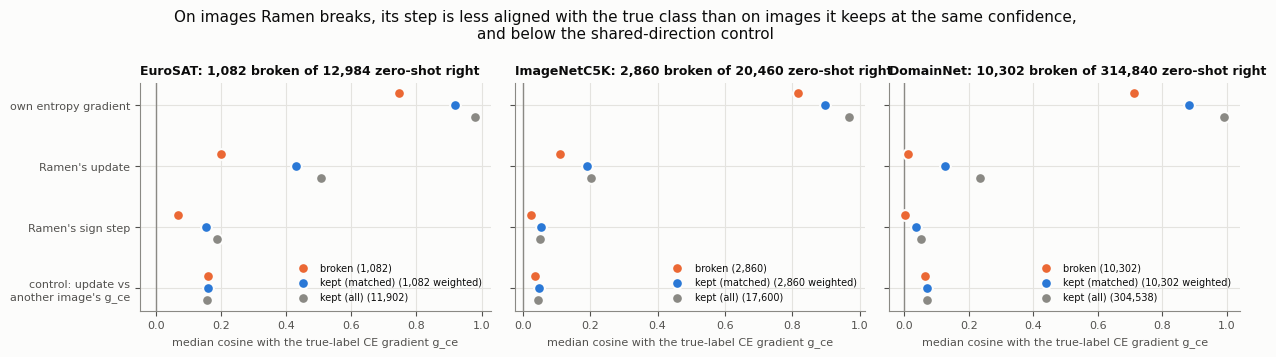

In [6]:
bp.plot_group_dots(bis); plt.show()

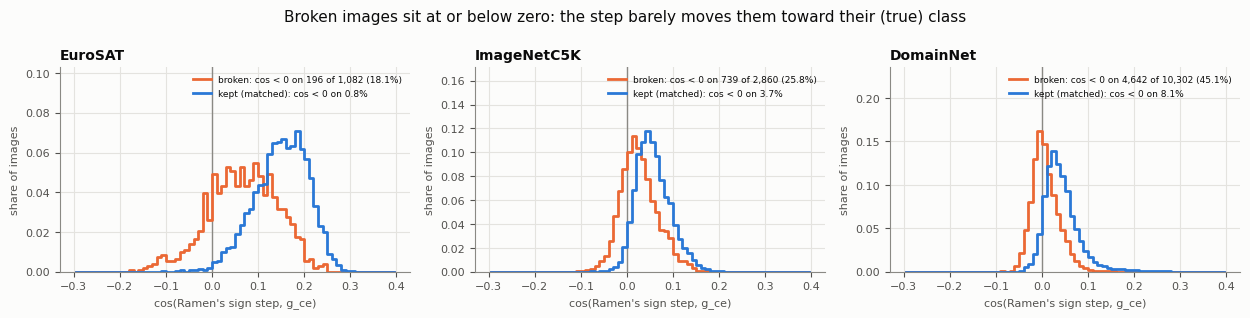

In [7]:
bp.plot_step_histograms(bis); plt.show()

### 4.2 Q2: does alignment predict breaking beyond confidence?

AUROC for picking broken images out of all zero-shot-right images (a lower value of the quantity = more likely broken). The logistic rows are 5-fold cross-validated. "Within confidence bins" averages the AUROC of the step's cosine inside each confidence bin, so confidence cannot contribute.

In [8]:
display(pd.DataFrame({ds: b.separability()['AUROC'] for ds, b in bis.items()}).round(3))

,EuroSAT,ImageNetC5K,DomainNet
"predictor of ""broken""",,,
"cos(Ramen's sign step, g_ce)",0.882,0.700,0.842
"cos(Ramen's update, g_ce)",0.830,0.664,0.756
"cos(own entropy gradient, g_ce)",0.840,0.785,0.904
"cos(sign step, g_ce) within confidence bins (15 bins, weighted by broken count)",NaN,NaN,0.780
"cos(sign step, g_ce) within confidence bins (16 bins, weighted by broken count)",0.813,NaN,NaN
"cos(sign step, g_ce) within confidence bins (20 bins, weighted by broken count)",NaN,0.722,NaN
"label-free: cos(update, own entropy gradient)",0.789,0.538,0.610
logistic: log p_zs(true) (5-fold CV),0.836,0.819,0.929
"logistic: log p_zs(true) + cos(sign step, g_ce) (5-fold CV)",0.907,0.862,0.951


Break rate by zero-shot confidence band (rows) and by quintile of $\cos(\operatorname{sign}\hat g, g^{CE})$ **within** the band (columns). Reading along a row holds confidence fixed.

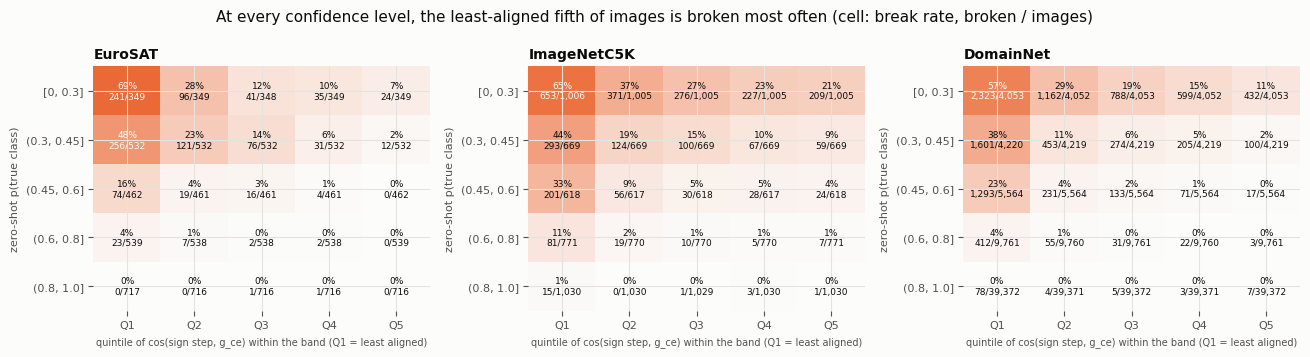

In [9]:
bp.plot_break_grid(bis); plt.show()

## 5. Mechanism

### 5.1 Q3: which part of the update is missing on broken images?

Mean additive shares of $\cos(\hat g, g^{CE})$ (means, not medians, so the parts add up).

In [10]:
for ds, b in bis.items():
    print(ds); display(b.decomposition().round(3))

EuroSAT


,the image's own entry,other entries of its own (zero-shot = true) queue,all other queues,"cos(Ramen's update, g_ce) (sum)",own entry stored
broken,0.033,0.119,0.045,0.197,1.0
kept (matched),0.046,0.222,0.161,0.429,1.0
kept (all),0.095,0.293,0.098,0.486,1.0


ImageNetC5K


,the image's own entry,other entries of its own (zero-shot = true) queue,all other queues,"cos(Ramen's update, g_ce) (sum)",own entry stored
broken,0.005,0.0,0.099,0.104,1.000
kept (matched),0.005,-0.0,0.187,0.192,0.999
kept (all),0.015,-0.0,0.187,0.202,1.000


DomainNet


,the image's own entry,other entries of its own (zero-shot = true) queue,all other queues,"cos(Ramen's update, g_ce) (sum)",own entry stored
broken,0.003,0.009,0.009,0.021,0.232
kept (matched),0.016,0.011,0.111,0.138,0.327
kept (all),0.042,0.016,0.182,0.240,0.315


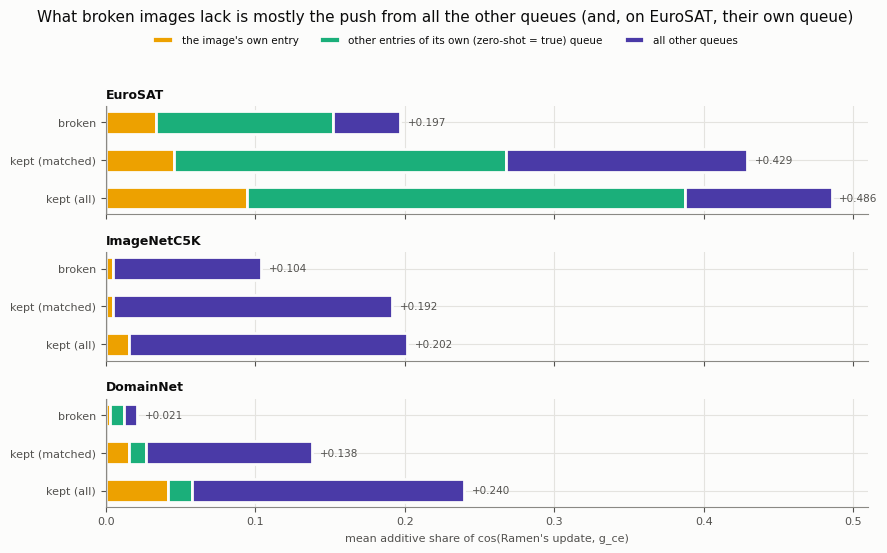

In [11]:
bp.plot_decomposition(bis); plt.show()

### 5.2 Q4: over the stream (DomainNet fp16 priority freeze)

On DomainNet most images after ~165k are not written into memory (the fp16 arrival counter saturates and a full queue only replaces an entry with a strictly larger priority), so they no longer retrieve their own entropy gradient. ImageNet-C and EuroSAT store almost every entry, so the comparison is only possible on DomainNet.

In [12]:
display(bis['DomainNet'].over_stream(n_bins=10).round(4))
print(bis['DomainNet'].own_entry_effect())

,slice,start,end,zs_right,broken,rate,stored,cos_step_broken,cos_step_kept
0,1,0,59678,31484,700,0.0222,1.0000,0.0157,0.1301
1,2,59679,118971,31484,811,0.0258,0.9850,0.0143,0.1162
2,3,118972,178919,31484,882,0.0280,0.7720,0.0081,0.0939
3,4,178924,238856,31484,1057,0.0336,0.2670,0.0025,0.0496
4,5,238857,298467,31484,1116,0.0354,0.0672,0.0019,0.0400
5,6,298468,357690,31484,1104,0.0351,0.0197,0.0004,0.0384
6,7,357693,417318,31484,1139,0.0362,0.0088,0.0010,0.0378
7,8,417320,476844,31484,1155,0.0367,0.0030,0.0002,0.0377
8,9,476845,536511,31484,1141,0.0362,0.0012,-0.0002,0.0382
9,10,536514,596004,31484,1197,0.0380,0.0014,0.0005,0.0379


zero-shot-right images with own entry stored                                           98,396 of 314,840 (31.3%)
break rate, stored / not stored (confidence-matched)                                               2.40% / 3.67%
freeze window (stream positions)                                      140,003-249,998, 57,866 images, 40% stored
break rate, stored / not stored (position- and confidence-matched)                     2.39% / 3.72% (220 cells)
dtype: object


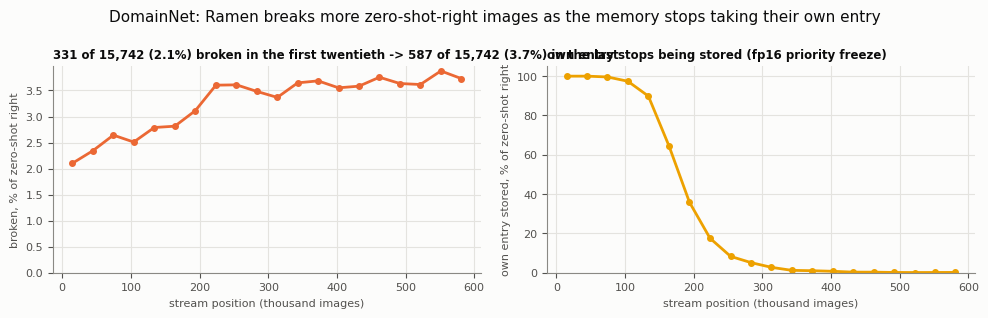

In [13]:
bp.plot_stream(bis['DomainNet']); plt.show()

### 5.3 Q4: where does Ramen move broken images?

Top classes Ramen predicts for broken images, and the true class most often moved there.

In [14]:
for ds, b in bis.items():
    t, n = b.destinations(class_names(ds))
    print(f'{ds}: broken images go to {n} distinct classes'); display(t)

EuroSAT: broken images go to 9 distinct classes


,Ramen predicts,broken images,share of broken,distinct true classes,most common true class
0,Highway,313,0.289279,9,River (136)
1,AnnualCrop,299,0.276340,6,PermanentCrop (162)
2,PermanentCrop,191,0.176525,5,Pasture (135)
3,Forest,85,0.078558,4,HerbaceousVegetation (77)
4,Residential,71,0.065619,7,Industrial (25)
5,Pasture,53,0.048983,3,HerbaceousVegetation (43)
6,River,41,0.037893,5,SeaLake (30)
7,Industrial,24,0.022181,7,PermanentCrop (8)
8,SeaLake,5,0.004621,2,Forest (4)


ImageNetC5K: broken images go to 815 distinct classes


,Ramen predicts,broken images,share of broken,distinct true classes,most common true class
0,jacamar,19,0.006643,11,indri (3)
1,Dandie Dinmont Terrier,16,0.005594,9,Clumber Spaniel (4)
2,English Setter,15,0.005245,7,Dalmatian (4)
3,ringlet butterfly,14,0.004895,2,gossamer-winged butterfly (13)
4,rock crab,14,0.004895,10,Dungeness crab (3)
5,gown,14,0.004895,4,overskirt (10)
6,mosquito net,14,0.004895,12,window shade (2)
7,Chesapeake Bay Retriever,14,0.004895,8,Golden Retriever (4)
8,dhole,14,0.004895,5,dingo (10)
9,Australian Kelpie,14,0.004895,6,German Shepherd Dog (6)


DomainNet: broken images go to 345 distinct classes


,Ramen predicts,broken images,share of broken,distinct true classes,most common true class
0,teapot,261,0.025335,60,coffee_cup (68)
1,whale,124,0.012036,27,dolphin (32)
2,helmet,116,0.011260,42,hat (13)
3,pillow,110,0.010678,36,envelope (29)
4,shovel,100,0.009707,32,axe (15)
5,tractor,98,0.009513,18,truck (34)
6,rhinoceros,94,0.009124,30,hedgehog (13)
7,sleeping_bag,93,0.009027,44,pillow (14)
8,mushroom,93,0.009027,28,flower (18)
9,cow,92,0.008930,26,horse (19)


## 6. Loss landscape around the zero-shot and the adapted point (Q5)

Section 4 measured *directions* (cosines). Here we look at the *loss surface itself* for 50 images per outcome group
(fewer where the group is smaller), drawn at random before the run. The landscape run replays Ramen on the same
stream, so first check that it is still Ramen, and that the slices are anchored correctly. (0, 0) must reproduce the
zero-shot logits and (1, 0) Ramen's logits.

In [15]:
ok = {ds: e.sanity_check_landscape() for ds, e in lexps.items()}
assert all(ok.values()), ok

  ga_landscape == Ramen (all images): 27,000 of 27,000
  chosen images recorded: 200 of 200
  label / zero-shot / Ramen prediction match the probe frame: 200 of 200
  cos(sign step, g_ce) matches the probe (|diff| < 1e-3): 200 of 200
  slice point (0, 0) predicts the zero-shot class: 200 of 200
  slice point (1, 0) predicts Ramen's class: 200 of 200
  max |logit diff| at (0, 0) vs zero-shot: 0.0000; at (1, 0) vs Ramen: 0.0000 (logit scale 100)


  ga_landscape == Ramen (all images): 75,000 of 75,000
  chosen images recorded: 200 of 200
  label / zero-shot / Ramen prediction match the probe frame: 200 of 200
  cos(sign step, g_ce) matches the probe (|diff| < 1e-3): 200 of 200
  slice point (0, 0) predicts the zero-shot class: 200 of 200
  slice point (1, 0) predicts Ramen's class: 200 of 200
  max |logit diff| at (0, 0) vs zero-shot: 0.0000; at (1, 0) vs Ramen: 0.0000 (logit scale 100)


  ga_landscape == Ramen (all images): 596,006 of 596,006
  chosen images recorded: 200 of 200
  label / zero-shot / Ramen prediction match the probe frame: 200 of 200
  cos(sign step, g_ce) matches the probe (|diff| < 1e-3): 200 of 200
  slice point (0, 0) predicts the zero-shot class: 200 of 200
  slice point (1, 0) predicts Ramen's class: 200 of 200
  max |logit diff| at (0, 0) vs zero-shot: 0.0000; at (1, 0) vs Ramen: 0.0000 (logit scale 100)


### 6.1 One step along three directions

Per outcome group: the median change of the true-label loss $L_i$ after one step ($t = 1$) along Ramen's step, the
oracle step and a random sign step of the same length, and how often each lowers the loss. Also the cosine between
Ramen's and the oracle step, and in embedding space how far the feature moves ($\lVert z_1 - z_0\rVert$, unit-norm
features) and the cosine of that move with the head's true-class ascent direction.

In [16]:
for ds, L in Ls.items():
    print(ds); display(L.group_summary().T)

EuroSAT


outcome,both right,fixed by Ramen,broken by Ramen,both wrong
images,50,50,50,50
"median CE change, Ramen's step",-0.389434,-1.54207,0.572361,1.045222
"median CE change, oracle step (sign of g_ce)",-0.4731,-1.765177,-0.905493,-1.838884
"median CE change, random sign step",-0.004707,-0.004614,0.01684,-0.019366
CE lowered by Ramen's step,50 of 50 (100.0%),50 of 50 (100.0%),11 of 50 (22.0%),15 of 50 (30.0%)
CE lowered by oracle step (sign of g_ce),48 of 50 (96.0%),50 of 50 (100.0%),50 of 50 (100.0%),50 of 50 (100.0%)
CE lowered by random sign step,28 of 50 (56.0%),25 of 50 (50.0%),24 of 50 (48.0%),32 of 50 (64.0%)
"median cos(Ramen's step, oracle step)",0.337229,0.147224,0.098896,-0.018229
median embedding move ||z1 - z0||,0.530888,0.679867,0.469682,0.579561
"median cos(z1 - z0, true-class ascent of the head)",0.179692,0.122428,-0.001428,-0.019647


ImageNetC5K


outcome,both right,fixed by Ramen,broken by Ramen,both wrong
images,50,50,50,50
"median CE change, Ramen's step",-0.123376,-1.571741,0.655662,0.002391
"median CE change, oracle step (sign of g_ce)",-0.550529,-2.244585,-1.134137,-3.706714
"median CE change, random sign step",-0.00027,0.029052,0.040484,0.001605
CE lowered by Ramen's step,38 of 50 (76.0%),50 of 50 (100.0%),7 of 50 (14.0%),25 of 50 (50.0%)
CE lowered by oracle step (sign of g_ce),49 of 50 (98.0%),48 of 50 (96.0%),50 of 50 (100.0%),50 of 50 (100.0%)
CE lowered by random sign step,25 of 50 (50.0%),23 of 50 (46.0%),21 of 50 (42.0%),23 of 50 (46.0%)
"median cos(Ramen's step, oracle step)",0.056353,0.074607,0.049003,0.005346
median embedding move ||z1 - z0||,0.417874,0.503647,0.463375,0.522768
"median cos(z1 - z0, true-class ascent of the head)",0.062388,0.124767,0.000435,0.049476


DomainNet


outcome,both right,fixed by Ramen,broken by Ramen,both wrong
images,50,50,50,50
"median CE change, Ramen's step",-0.039933,-1.232117,0.547462,0.064763
"median CE change, oracle step (sign of g_ce)",-0.08237,-2.165555,-0.942528,-3.334741
"median CE change, random sign step",0.000384,-0.053122,0.009287,-0.020842
CE lowered by Ramen's step,46 of 50 (92.0%),50 of 50 (100.0%),6 of 50 (12.0%),23 of 50 (46.0%)
CE lowered by oracle step (sign of g_ce),50 of 50 (100.0%),50 of 50 (100.0%),49 of 50 (98.0%),50 of 50 (100.0%)
CE lowered by random sign step,21 of 50 (42.0%),28 of 50 (56.0%),22 of 50 (44.0%),29 of 50 (58.0%)
"median cos(Ramen's step, oracle step)",0.087535,0.064578,0.013284,0.001903
median embedding move ||z1 - z0||,0.245003,0.31502,0.304388,0.293043
"median cos(z1 - z0, true-class ascent of the head)",0.115189,0.154655,-0.028421,0.014234


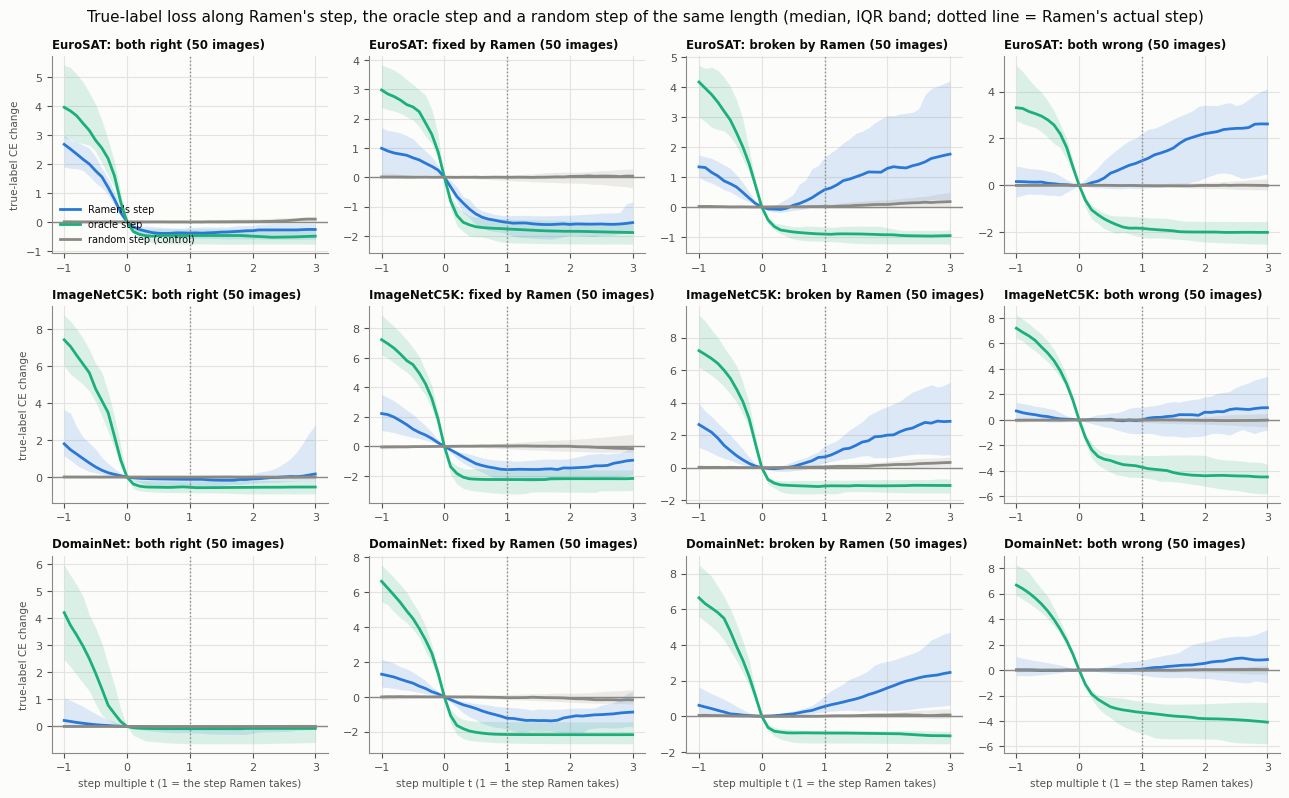

In [17]:
lp.plot_line_profiles(Ls); plt.show()

### 6.2 Two-dimensional slices, one typical image per group

Typical = the image whose loss change along Ramen's step is closest to its group's median. Top row: parameter
space (x = Ramen's step, y = the oracle step made orthogonal to it). Bottom row: embedding space (x = $z_1 - z_0$,
y = the head's true-class direction made orthogonal to it). Darker = higher true-label loss; the aqua region
predicts the true class.

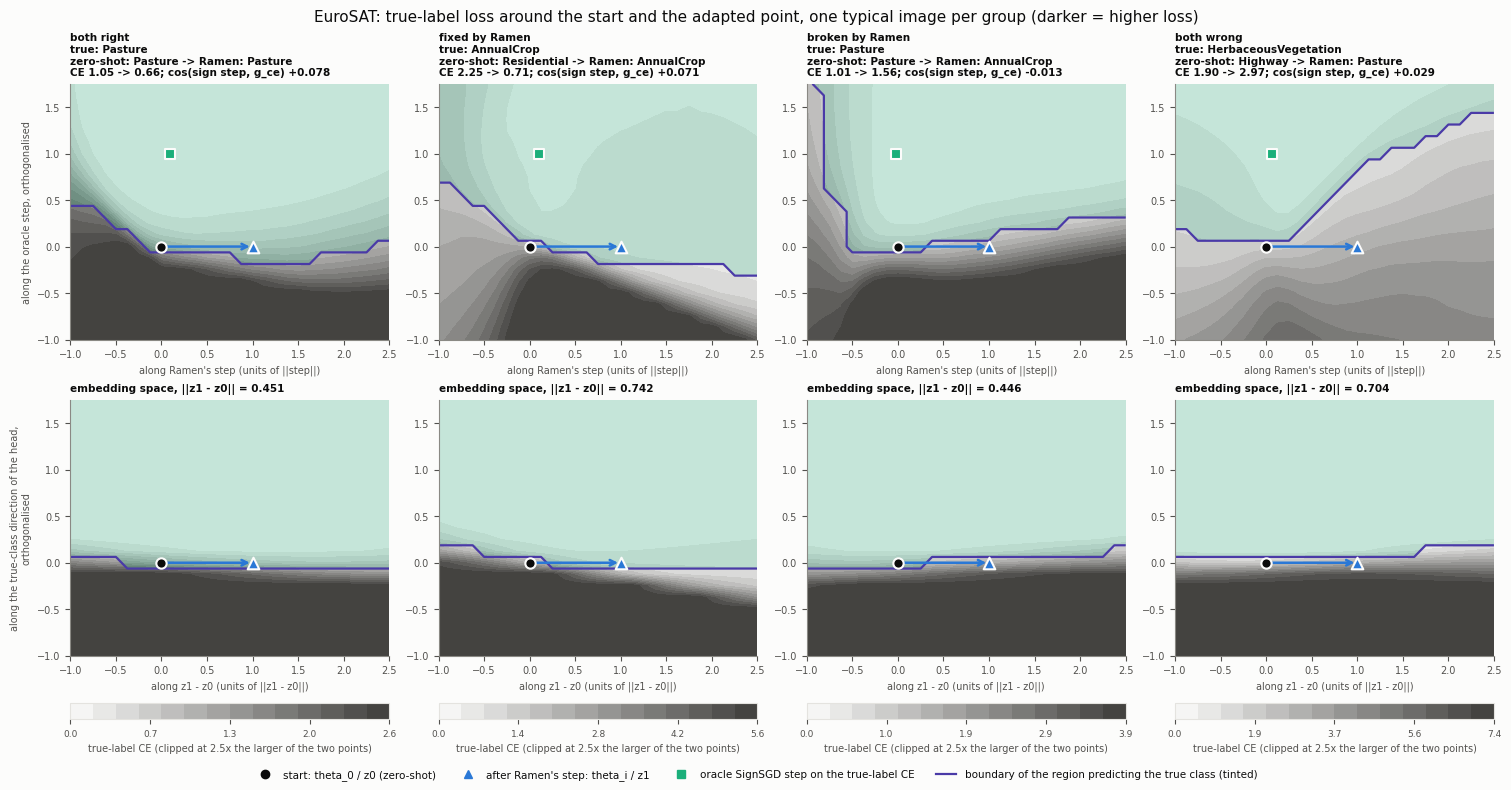

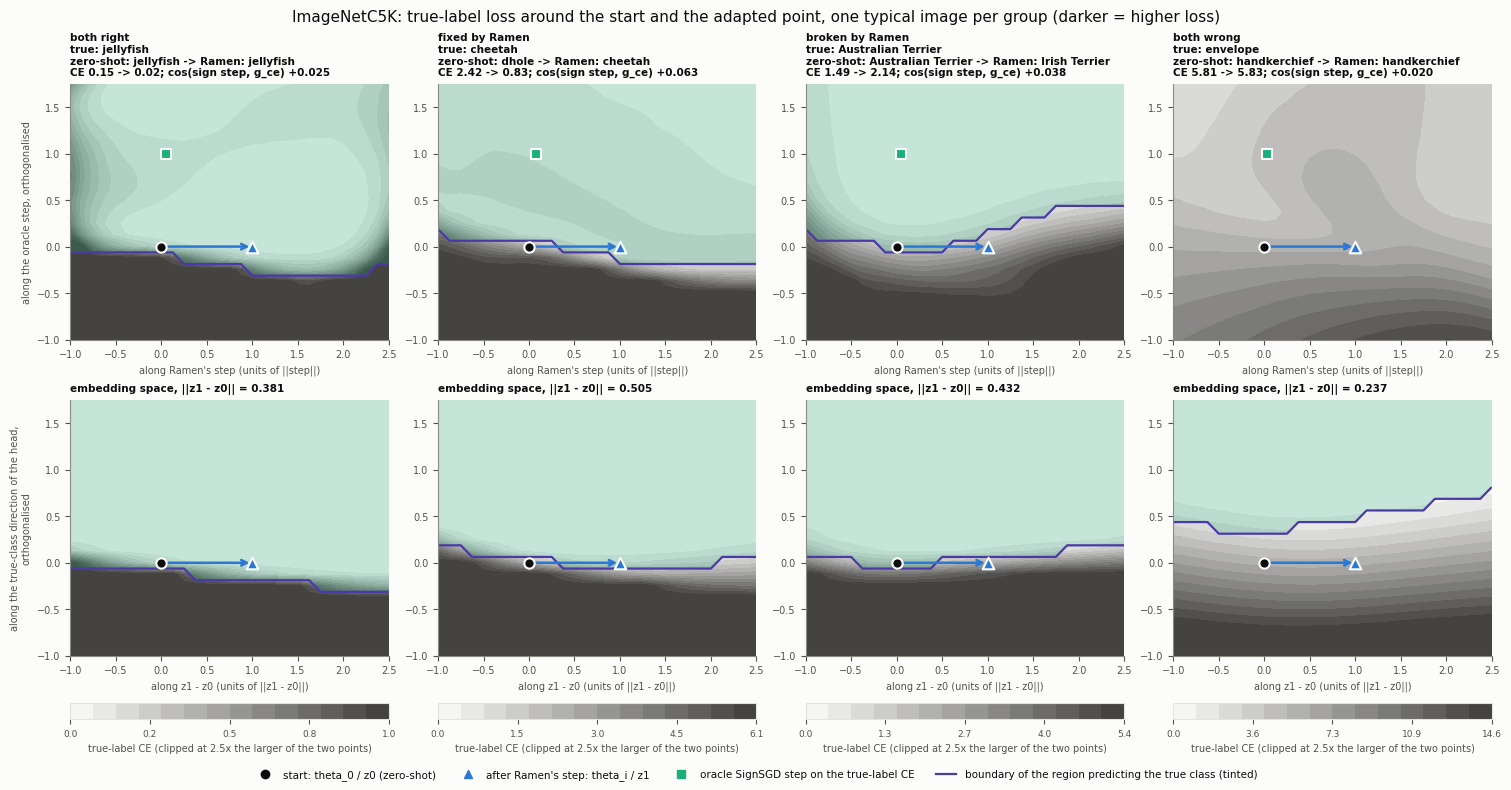

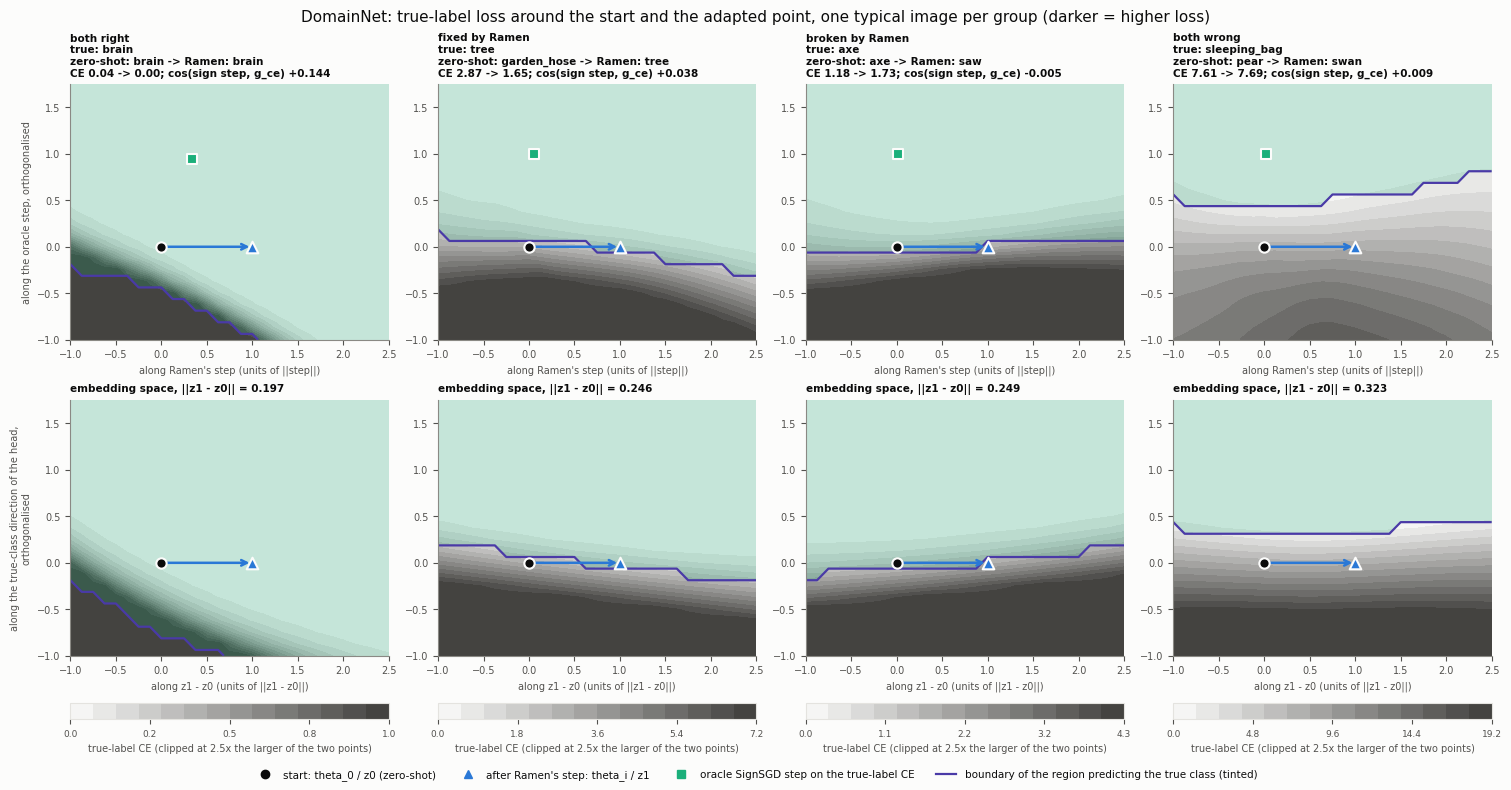

In [18]:
for ds in DATASETS:
    lp.plot_slices(Ls[ds], ds, class_names(ds)); plt.show()

## 7. Interpretation

**What the numbers show (seed 0, three datasets).**
- **Broken images are rare and low-confidence.** EuroSAT 1,082 of 12,984 zero-shot-right images (8.3%), ImageNet-C
  2,860 of 20,460 (14.0%), DomainNet 10,302 of 314,840 (3.3%). Their median zero-shot $p(\text{true})$ is 0.32 /
  0.25 / 0.29 against 0.62 / 0.60 / 0.91 for kept images. Confidence alone picks them out with AUROC 0.84 / 0.82 /
  0.93.
- **Q1: at the same confidence, Ramen's step is worse on broken images.** Median $\cos(\operatorname{sign}\hat g,
  g^{CE})$: broken vs kept (matched) $+0.068$ vs $+0.154$ (EuroSAT), $+0.023$ vs $+0.052$ (ImageNet-C), $+0.003$ vs
  $+0.036$ (DomainNet). The step points away from the true class on 196 of 1,082 (18.1%), 739 of 2,860 (25.8%) and
  4,642 of 10,302 (45.1%) broken images, against 0.8% / 3.7% / 8.1% of matched kept images. On every dataset the
  broken median sits **below the shared-direction control** ($+0.159$ / $+0.036$ / $+0.065$): on these images Ramen's
  update has lost even the generic component every image gets.
- **Q2: alignment adds to confidence.** Inside confidence bins the step's cosine still separates broken from kept
  (AUROC 0.81 / 0.72 / 0.78). Adding it to confidence raises the cross-validated AUROC 0.836 → 0.907 / 0.819 →
  0.862 / 0.929 → 0.951. In the lowest confidence band ($p \le 0.3$) the least-aligned fifth is broken 69% / 65% /
  57% of the time, the most-aligned fifth 7% / 21% / 11%.
- **The image's own direction is also worse.** At matched confidence, $\cos(g_i, g^{CE})$ is 0.75 vs 0.92 / 0.82 vs
  0.90 / 0.71 vs 0.88 (medians). So "broken = a good own direction averaged away" (notebooks 01–03) is only half
  right: the own direction is good, but less good than for kept images at the same confidence. What this
  means is a **hypothesis** not tested here: at low confidence the entropy gradient partly sharpens the runner-up
  class too, which the CE gradient does not.
- **Q3: what is missing is mostly the pull from the bulk of other queues.** Mean share of
  $\cos(\hat g, g^{CE})$ from all other queues, broken vs matched kept: $+0.045$ vs $+0.161$ (EuroSAT), $+0.099$ vs
  $+0.187$ (ImageNet-C), $+0.009$ vs $+0.111$ (DomainNet). On EuroSAT the image's own queue also drops ($+0.119$ vs
  $+0.222$). On DomainNet and ImageNet-C the own queue gives almost nothing to anyone (1/|C| weight, as in
  notebooks 01–03), and the own entry is small everywhere ($\le 0.05$).
- **Q4: DomainNet breaks more once the memory stops storing images.** The break rate rises from 2.1% to 3.7% of
  zero-shot-right images over the stream (first vs last twentieth) as the share with their own entry stored falls
  from ~100% to ~0% (fp16 priority freeze). Inside the freeze window, matched on stream position and confidence,
  the break rate is 2.39% with the own entry stored vs 3.72% without. Over the same stream the kept images'
  alignment also decays (median $\cos(\operatorname{sign}\hat g, g^{CE})$ 0.13 → 0.04).
- **Destinations.** DomainNet breaks are spread over all 345 classes (largest: teapot 261 of 10,302, 2.5%, mostly
  from coffee cup; whale from dolphin; pillow from envelope). ImageNet-C breaks go to 815 classes, at most 19 each,
  so no sink. EuroSAT breaks concentrate on Highway (313, 28.9%, mostly from River) and AnnualCrop (299, mostly
  from PermanentCrop).

- **Q5 (section 6): the loss landscape, 50 images per group.** All three runs replay Ramen exactly
  (predictions equal on 27,000 / 75,000 / 596,006 images; slice anchors reproduce the zero-shot and Ramen logits on
  200 of 200 images per dataset, max logit difference 0.0000).
  - *Step length is not the problem; direction is.* An oracle SignSGD step of the same length lowers the true-label
    loss on 50 of 50 images in every group but one (broken DomainNet: 49 of 50). On zero-shot-wrong images it
    reaches the true class at a tenth to a fifth of a step (median $t$ = 0.10–0.20).
  - *Random steps of that length do almost nothing* (median loss change between −0.053 and +0.040 in every group).
    Away from a few directions, the surface around $\theta_0$ is flat at this scale. Ramen's step does move the loss
    by O(1), so it finds loss-relevant directions. It moves the loss the way the zero-shot prediction points: down
    where zero-shot is right (both right −0.39 / −0.12 / −0.04, EuroSAT / ImageNet-C / DomainNet), down strongly
    on fixed images (−1.54 / −1.57 / −1.23).
  - *Broken images:* Ramen's step raises the loss (+0.57 / +0.66 / +0.55) and lowers it on only 11 / 7 / 6 of
    50. The class flips at about half a step (median $t$ = 0.50 / 0.55 / 0.45). The oracle step of the same length
    would lower the loss on every one (−0.91 / −1.13 / −0.94) and never flips them.
  - *Both wrong:* on EuroSAT Ramen's step raises the loss (+1.05, sharpening the wrong class); on ImageNet-C and
    DomainNet it barely moves it (+0.002 / +0.06), the "cancel, don't redirect" pattern of notebooks 01–03. The
    oracle step would lower it by −1.84 / −3.71 / −3.33.
  - *Geometry.* Ramen's step and the oracle step are close to orthogonal (median cosine 0.00–0.34, highest on
    EuroSAT both-right). In the slices, Ramen's step runs roughly along the boundary of the true-class region, which
    lies in the orthogonal oracle direction.
  - *Embedding space.* Features move far on the unit sphere (median $\lVert z_1 - z_0\rVert$ 0.47–0.68 EuroSAT,
    0.42–0.52 ImageNet-C, 0.25–0.32 DomainNet). On broken images the move is orthogonal to the head's true-class
    direction (median cosine −0.001 / +0.000 / −0.028), against +0.06 to +0.18 on both-right and fixed images.
    Ramen moves broken images a long way, but not toward or away from their class: sideways, until a near
    competitor takes over.

**What this does not show.**
- **Part of the alignment–break link is expected by construction.** The first-order change of the true-class loss is
  proportional to $\cos(\operatorname{sign}\hat g, g^{CE})$, so images whose $p(\text{true})$ falls must lean toward
  low cosines. The non-trivial facts are the size of the gap at matched confidence, the many negative cosines, the
  values below the control, and which part of the update is missing.
- **The own-entry effect is an association.** Whether an entry is stored also depends on its class (a queue that is
  not yet full always stores). The causal test is Ramen with `priority_fp32: true` on the mixed DomainNet stream,
  which has not been run (only the sequential stream has: +0.22 there).
- Section 6: 50 images per group, equal-sized groups, not weighted by group size. The 2D slices are one image
  each ("typical" by one criterion), on a 0.125 grid, so boundaries look jagged. A random sign direction is nearly
  orthogonal to any fixed gradient in $D = 39{,}936$ dimensions, so its near-zero effect is expected: it shows the
  surface is flat in generic directions, not that it is flat everywhere. The oracle step uses the true label: a
  ceiling for this step length, not something a test-time method can do.
- One seed. Oracle measurement, not a method.

**What it means for a fix.** A confidence gate cannot separate breaks from fixes (dead end: both are low-margin).
The probe shows the extra signal is the step's alignment, which needs $y_i$. The one label-free quantity logged
here, $\cos(\hat g_i, g_i)$, is weak (AUROC 0.79 / 0.54 / 0.61), and it would also have to leave fixes alone.

**Next step.** Run Ramen with fp32 priorities on mixed DomainNet seed 0 (~40 min, a config override): if the
freeze causes breaks, the break count should fall from 10,302 toward the pre-freeze rate (~2.2%, about 7,000). If breaks
stay at ~3.3%, the stored/not-stored gap is a class effect. Expect a small accuracy change at most: on mixed CIFAR-10-C /
CIFAR-100-C seed 0, fp32 priorities change accuracy by +0.05 / −0.00 (cached `fp32prio` runs), and fixes may move too.


## 8. Glossary

| term | meaning |
|---|---|
| zero-shot right / wrong | CLIP's prediction with the frozen model ($\hat y_i$) is / is not the true label |
| broken (by Ramen) | zero-shot right, Ramen's prediction wrong |
| kept | zero-shot right and Ramen right |
| kept (matched) | kept images reweighted to the broken images' distribution of zero-shot $p(\text{true})$ (20 quantile bins) |
| $g^{CE}$ | **oracle** gradient of $-\log p(\text{true class})$ at the frozen parameters; uses the true label |
| sign step | $-\eta\,\operatorname{sign}(\hat g)$, what Ramen's SignSGD actually applies |
| control | cosine of image $i$'s update with *another* image's $g^{CE}$; a direction all images share |
| own entry | the image's own $(z, g, H)$, written to memory before retrieval; retrieved at distance ~0 if stored |
| own queue | the queue of the zero-shot class; for zero-shot-right images this is the true class |
| fp16 priority freeze | Ramen's arrival counter is fp16; after ~65k inserts new priorities stop exceeding stored ones, so full queues stop accepting entries |
| AUROC | probability that a random broken image has a lower value of the quantity than a random kept image (0.5 = no signal) |
| loss landscape / slice | the true-label loss evaluated on a 2D plane (or 1D line) of parameters or embeddings through the start point |
| oracle step | $-\eta\operatorname{sign}(g^{CE})$: the SignSGD step on the true-label loss, same length as Ramen's step |
| random step | $-\eta\operatorname{sign}(\xi)$, $\xi$ Gaussian: same length, no information (control) |
| $z_0$, $z_1$ | normalised image feature before / after Ramen's step |
| additive share | $\langle \text{part}, g^{CE}\rangle / (\lVert\hat g\rVert\lVert g^{CE}\rVert)$; the parts sum to $\cos(\hat g, g^{CE})$ |
